# Fase 2 – Data Understanding
Esta fase segue as quatro tarefas da metodologia CRISP-DM. Em cada tarefa são aplicados os passos do processo EDA correspondentes:

| Tarefa CRISP-DM | Passos EDA |
|---|---|
| 2.1 Recolha inicial dos dados | Passos 1 e 2 – Compreender e inspecionar |
| 2.2 Descrição dos dados | Passos 4 e 6 – Explorar e visualizar |
| 2.3 Exploração dos dados | Passos 5 e 8 – Transformar e reportar |
| 2.4 Verificação da qualidade | Passos 3 e 7 – Ausentes e outliers |

Nesta fase os problemas são **identificados**; a sua correção é feita na Fase 3 – Data Preparation.

## 2.1 Recolha Inicial dos Dados (Collect Initial Data)
> **CRISP-DM:** obter os dados listados nos recursos do projeto e carregá-los na ferramenta de análise. Output: *Initial Data Collection Report*, com os datasets obtidos, a sua localização, o método de obtenção e os problemas encontrados, bem como a forma como foram resolvidos.
>
> **Passos EDA:** 1 – Compreensão do problema e dos dados; 2 – Importação e inspeção inicial.

**Contexto (do Business Understanding):** os dados provêm de uma UCIN e estão em duas tabelas ligadas pelo código de episódio. O episódio é um acontecimento clínico e não identifica o bebé. Os sinais vitais são horários e as patologias diárias.

In [3]:
# =============================================================================
# 2.1.1 Bibliotecas
# pandas: tabelas | numpy: cálculos | matplotlib/seaborn: gráficos
# os: verificar ficheiros na pasta de dados
# =============================================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

In [4]:
# =============================================================================
# 2.1.2 Localização dos dados
# Os ficheiros foram descarregados da competição Kaggle da UC e guardados na
# pasta "dados/". Lista o conteúdo da pasta e o tamanho de cada ficheiro,
# para documentar exatamente o que foi obtido.
# =============================================================================
PASTA_DADOS = "dados/"
FICH_SINAIS = "sinais_vitais_por_hora.csv"
FICH_PATOLOGIAS = "patologias_por_dia.csv"

for f in sorted(os.listdir(PASTA_DADOS)):
    tamanho_kb = os.path.getsize(os.path.join(PASTA_DADOS, f)) / 1024
    print(f"{f:45s} {tamanho_kb:8.1f} KB")

patologias_por_dia.csv                            28.1 KB
sinais_vitais_por_hora.csv                       367.2 KB


In [3]:
# =============================================================================
# 2.1.3 Inspeção do ficheiro em bruto
# Antes de usar o pandas, lê as primeiras linhas como texto. Assim confirmamos
# o separador (vírgula ou ponto e vírgula), o separador decimal e se há
# cabeçalho. Qualquer surpresa aqui é um "problema encontrado" a registar.
# =============================================================================
for fich in [FICH_SINAIS, FICH_PATOLOGIAS]:
    print(f"--- {fich} ---")
    with open(os.path.join(PASTA_DADOS, fich), encoding="utf-8", errors="replace") as f:
        for _ in range(5):
            print(f.readline().rstrip())
    print()

--- sinais_vitais_por_hora.csv ---
episodio,data,hora,sat_o2,puls_rate,perfusion
EP001,2024-01-30,9,93.5,158.63,0.99
EP001,2024-01-30,10,92.3,155.86,0.86
EP002,2024-01-30,10,94.31,133.2,0.91
EP001,2024-01-30,11,93.96,150.0,1.13

--- patologias_por_dia.csv ---
episodio,data,patologia
EP001,2024-01-30,Displasia broncopulmonar
EP001,2024-01-30,Refluxo gastroesofágico
EP003,2024-01-30,Doença das membranas hialinas
EP003,2024-01-30,Doença das membranas hialinas



In [5]:
# =============================================================================
# 2.1.4 Carregamento dos dados
# Tenta ler em UTF-8; se falhar (acentos mal codificados), usa latin-1.
# A codificação usada fica registada para o relatório de recolha.
# =============================================================================
def carregar_csv(nome):
    caminho = os.path.join(PASTA_DADOS, nome)
    try:
        df = pd.read_csv(caminho, encoding="utf-8")
        cod = "utf-8"
    except UnicodeDecodeError:
        df = pd.read_csv(caminho, encoding="latin-1")
        cod = "latin-1"
    print(f"{nome}: carregado com codificação {cod}")
    return df

df_sinais = carregar_csv(FICH_SINAIS)
df_patologias = carregar_csv(FICH_PATOLOGIAS)

sinais_vitais_por_hora.csv: carregado com codificação utf-8
patologias_por_dia.csv: carregado com codificação utf-8


In [5]:
# =============================================================================
# 2.1.5 Volumetria
# Nº de registos e campos de cada tabela. Confirma também os valores
# referidos no relatório de Business Understanding (9 857 e 696 registos).
# =============================================================================
for nome, df, esperado in [("Sinais vitais", df_sinais, 9857),
                           ("Patologias", df_patologias, 696)]:
    linhas, colunas = df.shape
    ok = "OK" if linhas == esperado else f"DIFERENTE do relatório ({esperado})"
    print(f"{nome}: {linhas} registos x {colunas} campos -> {ok}")

Sinais vitais: 9857 registos x 6 campos -> OK
Patologias: 696 registos x 3 campos -> OK


In [6]:
# =============================================================================
# 2.1.6 Campos obtidos vs. campos esperados
# Compara os nomes das colunas com o dicionário de dados. Apanha espaços
# escondidos, maiúsculas diferentes ou colunas a mais/em falta.
# =============================================================================
esperado = {
    "Sinais vitais": ["episodio", "data", "hora", "sat_o2", "puls_rate", "perfusion"],
    "Patologias": ["episodio", "data", "patologia"],
}
for nome, df in [("Sinais vitais", df_sinais), ("Patologias", df_patologias)]:
    obtidas = df.columns.tolist()
    print(f"{nome}: {obtidas}")
    print("   Em falta:", set(esperado[nome]) - set(obtidas) or "nenhuma")
    print("   A mais:  ", set(obtidas) - set(esperado[nome]) or "nenhuma")

Sinais vitais: ['episodio', 'data', 'hora', 'sat_o2', 'puls_rate', 'perfusion']
   Em falta: nenhuma
   A mais:   nenhuma
Patologias: ['episodio', 'data', 'patologia']
   Em falta: nenhuma
   A mais:   nenhuma


In [7]:
# =============================================================================
# 2.1.7 Tipos atribuídos e valores não nulos
# Esperado: hora -> int64 | sat_o2, puls_rate, perfusion -> float64
#           episodio, data, patologia -> object (texto)
# Uma coluna numérica lida como object indica valores não numéricos lá dentro
# (gralha a analisar na tarefa 2.4).
# =============================================================================
print("===== SINAIS VITAIS =====")
df_sinais.info()
print("\n===== PATOLOGIAS =====")
df_patologias.info()

===== SINAIS VITAIS =====
<class 'pandas.DataFrame'>
RangeIndex: 9857 entries, 0 to 9856
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   episodio   9857 non-null   str  
 1   data       9857 non-null   str  
 2   hora       9857 non-null   int64
 3   sat_o2     9813 non-null   str  
 4   puls_rate  9793 non-null   str  
 5   perfusion  9815 non-null   str  
dtypes: int64(1), str(5)
memory usage: 462.2 KB

===== PATOLOGIAS =====
<class 'pandas.DataFrame'>
RangeIndex: 696 entries, 0 to 695
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   episodio   696 non-null    str  
 1   data       696 non-null    str  
 2   patologia  684 non-null    str  
dtypes: str(3)
memory usage: 16.4 KB


In [8]:
# =============================================================================
# 2.1.8 Primeiras linhas e amostra aleatória
# head() mostra o início do ficheiro; sample() mostra linhas de todo o
# ficheiro, onde é mais provável aparecerem gralhas.
# random_state fixa a amostra para ser sempre a mesma.
# =============================================================================
display(df_sinais.head())
display(df_sinais.sample(8, random_state=42))
display(df_patologias.head())
display(df_patologias.sample(8, random_state=42))

,episodio,data,hora,sat_o2,puls_rate,perfusion
0,EP001,2024-01-30,9,93.5,158.63,0.99
1,EP001,2024-01-30,10,92.3,155.86,0.86
2,EP002,2024-01-30,10,94.31,133.2,0.91
3,EP001,2024-01-30,11,93.96,150.0,1.13
4,EP002,2024-01-30,11,91.19,139.79,1.55


,episodio,data,hora,sat_o2,puls_rate,perfusion
8376,EP026,2024-04-14,5,95.24,156.27,1.19
500,EP001,2024-02-04,19,92.82,162.51,1.1
8919,EP034,2024-04-16,18,98.0,145.38,1.46
872,EP001,2024-02-08,22,91.13,154.28,1.12
5414,EP022,2024-03-17,7,94.4,149.55,2.29
5558,EP025,2024-03-18,2,97.49,126.09,1.17
7185,EP026,2024-04-03,20,94.44,146.92,0.63
7048,EP026,2024-04-01,1,96.09,157.7,1.23


,episodio,data,patologia
0,EP001,2024-01-30,Displasia broncopulmonar
1,EP001,2024-01-30,Refluxo gastroesofágico
2,EP003,2024-01-30,Doença das membranas hialinas
3,EP003,2024-01-30,Doença das membranas hialinas
4,EP003,2024-01-30,Icterícia neonatal


,episodio,data,patologia
674,EP026,2024-04-19,Displasia broncopulmonar
314,EP016,2024-03-05,Doença das membranas hialinas
611,EP039,2024-04-13,Doença das membranas hialinas
431,EP027,2024-03-17,Citomegalovírus
552,EP027,2024-04-03,Citomegalovírus
211,EP015,2024-02-24,Doença das membranas hialinas
538,EP032,2024-03-30,Sépsis
176,EP001,2024-02-20,Displasia broncopulmonar


In [9]:
# =============================================================================
# 2.1.9 Ligação entre as duas fontes
# O CRISP-DM lembra que, com várias fontes, a integração é uma questão a
# considerar já aqui. Verifica se as tabelas falam dos mesmos episódios.
# (A integração propriamente dita é feita na Fase 3.)
# =============================================================================
ep_sinais = set(df_sinais["episodio"])
ep_patologias = set(df_patologias["episodio"])

print("Episódios nos sinais vitais:", len(ep_sinais))
print("Episódios nas patologias:   ", len(ep_patologias))
print("Em ambas as tabelas:        ", len(ep_sinais & ep_patologias))
print("Só nos sinais vitais:       ", len(ep_sinais - ep_patologias))
print("Só nas patologias:          ", len(ep_patologias - ep_sinais))

Episódios nos sinais vitais: 58
Episódios nas patologias:    45
Em ambas as tabelas:         40
Só nos sinais vitais:        18
Só nas patologias:           5


In [10]:
# =============================================================================
# 2.1.10 Episódios presentes só numa das tabelas
# Lista os códigos para documentar a discrepância. Se houver códigos
# parecidos (ex.: "EP01" vs "EP001", "ep001"), é gralha e não falta de dados.
# A análise completa é feita na tarefa 2.4.
# =============================================================================
print("Só nas patologias:   ", sorted(ep_patologias - ep_sinais))
print("Só nos sinais vitais:", sorted(ep_sinais - ep_patologias))

Só nas patologias:    [' EP009', ' EP020', 'EP 018', 'EP 037', 'ep029']
Só nos sinais vitais: [' EP011', ' EP016', ' EP027', 'EP 016', 'EP 026', 'EP 034', 'EP 036', 'EP007', 'EP012', 'EP021', 'EP028', 'EP031', 'EP035', 'EP044', 'EP047', 'ep016', 'ep019', 'ep023']


### Relatório de Recolha Inicial dos Dados

**Datasets obtidos**

| Dataset | Localização | Método de obtenção | Registos x campos | Formato |
|---|---|---|---|---|
| sinais_vitais_por_hora.csv | dados/ | Download da competição Kaggle da UC | 9 857 x 6 | CSV, separador vírgula, ponto decimal, UTF-8 |
| patologias_por_dia.csv | dados/ | Download da competição Kaggle da UC | 696 x 3 | CSV, separador vírgula, ponto decimal, UTF-8 |

Os dois ficheiros foram carregados em Python (pandas) sem erros de leitura. O número de registos coincide com o indicado no Business Understanding e todos os campos do dicionário de dados estão presentes, sem colunas adicionais. Não existem outras fontes de dados para o projeto.

**Problemas encontrados**

| Problema | Onde | Detalhe | Resolução |
|---|---|---|---|
| Colunas numéricas lidas como texto | sat_o2, puls_rate, perfusion | Existem valores não numéricos nestas colunas | Identificar os valores na tarefa 2.4; converter para número na Fase 3 |
| Valores em falta | sat_o2 (44), puls_rate (64), perfusion (42), patologia (12) | Representados como células vazias | Caracterizar na tarefa 2.4; definir tratamento na Fase 3 |
| Códigos de episódio inconsistentes | Ambas as tabelas | Espaço no início (" EP009"), espaço no meio ("EP 018") e minúsculas ("ep029") | Normalizar os códigos (remover espaços e converter para maiúsculas) na Fase 3 |

**Correspondência entre tabelas**

Sem normalização, os sinais vitais têm 58 códigos de episódio e as patologias 45, com 40 em comum. A maior parte da diferença deve-se às gralhas nos códigos, que fazem o mesmo episódio aparecer com vários códigos. Depois de normalizados, os episódios só com patologias deverão desaparecer. Ficam apenas com sinais vitais, e sem patologias registadas, oito episódios: EP007, EP012, EP021, EP028, EP031, EP035, EP044 e EP047. Estes números serão confirmados na tarefa 2.4.

**Nota sobre integração:** as duas fontes ligam-se pelos campos `episodio` e `data`, mas têm granularidades diferentes (sinais vitais por hora e patologias por dia). A integração será feita na Fase 3, depois de corrigidos os códigos de episódio e os restantes problemas de qualidade.

## 2.2 Descrição dos Dados (Describe Data)
> **CRISP-DM:** examinar as propriedades "de superfície" dos dados obtidos: formato, quantidade (registos e campos de cada tabela), identidade dos campos e outras características gerais. Avaliar se os dados satisfazem os requisitos do projeto. Output: *Data Description Report*.
>
> **Passos EDA:** 4 – Medidas de tendência central e dispersão; 6 – Visualização (análise univariada).

**Nota:** para calcular estatísticas é criada uma cópia de trabalho de cada tabela, com os valores numéricos convertidos e os códigos de episódio normalizados. Os valores que não é possível converter são excluídos das estatísticas e analisados na tarefa 2.4. Os dados originais não são alterados.

### 2.2.1 Identidade dos campos

| Tabela | Campo | Descrição | Tipo | Unidade / domínio |
|---|---|---|---|---|
| Sinais vitais | episodio | Código do episódio clínico | Qualitativo nominal (identificador) | EPxxx |
| Sinais vitais | data | Dia do registo | Data | AAAA-MM-DD |
| Sinais vitais | hora | Hora do dia (9 = 09:00–09:59) | Quantitativo discreto (cíclico) | 0–23 |
| Sinais vitais | sat_o2 | Saturação periférica de oxigénio, valor típico da hora | Quantitativo contínuo | %, 0–100 |
| Sinais vitais | puls_rate | Frequência de pulso, valor típico da hora | Quantitativo contínuo | bpm |
| Sinais vitais | perfusion | Índice de perfusão, valor típico da hora | Quantitativo contínuo | % |
| Patologias | episodio | Código do episódio clínico | Qualitativo nominal (identificador) | EPxxx |
| Patologias | data | Dia do registo | Data | AAAA-MM-DD |
| Patologias | patologia | Patologia confirmada no registo clínico | Qualitativo nominal | 13 valores possíveis |

In [6]:
# =============================================================================
# 2.2.2 Cópias de trabalho para a descrição
# - episodio: remove espaços e passa a maiúsculas (" ep 016" -> "EP016")
# - data: converte para datas; datas inválidas ficam vazias (NaT)
# - sinais vitais: converte para número; texto inválido fica vazio (NaN)
# - patologia: remove espaços nas pontas e uniformiza maiúsculas
# Conta quantos valores existiam mas não foi possível converter.
# Os DataFrames originais (df_sinais, df_patologias) ficam intactos.
# =============================================================================
sv = df_sinais.copy()
pat = df_patologias.copy()

for df in (sv, pat):
    df["episodio"] = df["episodio"].str.replace(" ", "", regex=False).str.upper()
    df["data_dt"] = pd.to_datetime(df["data"], format="%Y-%m-%d", errors="coerce")

VITAIS = ["sat_o2", "puls_rate", "perfusion"]
for col in VITAIS:
    convertido = pd.to_numeric(sv[col], errors="coerce")
    falhas = (convertido.isna() & sv[col].notna()).sum()
    print(f"{col}: {falhas} valores não convertíveis para número")
    sv[col] = convertido

pat["patologia"] = pat["patologia"].str.strip().str.capitalize()

print("\nDatas inválidas -> sinais:", sv["data_dt"].isna().sum(),
      "| patologias:", pat["data_dt"].isna().sum())

sat_o2: 3 valores não convertíveis para número
puls_rate: 7 valores não convertíveis para número
perfusion: 5 valores não convertíveis para número

Datas inválidas -> sinais: 18 | patologias: 10


In [7]:
# =============================================================================
# 2.2.3 Quantidade de dados
# Nº de episódios (com códigos normalizados), período coberto e quanto tempo
# cada episódio está registado (dias e horas). A duração por episódio é a
# base da futura variável "duração do internamento" (objetivo DM2).
# =============================================================================
print("Episódios (normalizados) -> sinais:", sv["episodio"].nunique(),
      "| patologias:", pat["episodio"].nunique(),
      "| total:", len(set(sv["episodio"]) | set(pat["episodio"])))
print("Período dos sinais vitais:", sv["data_dt"].min().date(), "->", sv["data_dt"].max().date())
print("Período das patologias:   ", pat["data_dt"].min().date(), "->", pat["data_dt"].max().date())

por_episodio = sv.groupby("episodio").agg(
    registos=("hora", "size"),
    dias_distintos=("data_dt", "nunique"),
    primeiro_dia=("data_dt", "min"),
    ultimo_dia=("data_dt", "max"),
)
por_episodio["duracao_dias"] = (por_episodio["ultimo_dia"] - por_episodio["primeiro_dia"]).dt.days + 1

print("\nResumo por episódio (sinais vitais):")
display(por_episodio[["registos", "dias_distintos", "duracao_dias"]].describe().round(1))

Episódios (normalizados) -> sinais: 47 | patologias: 39 | total: 47
Período dos sinais vitais: 2024-01-30 -> 2024-04-20
Período das patologias:    2024-01-30 -> 2024-04-20

Resumo por episódio (sinais vitais):


,registos,dias_distintos,duracao_dias
count,47.0,47.0,47.0
mean,209.7,9.6,9.7
std,198.4,8.2,8.3
min,4.0,1.0,1.0
25%,62.5,3.5,3.5
50%,143.0,7.0,7.0
75%,301.5,13.5,13.5
max,853.0,36.0,36.0


In [8]:
# =============================================================================
# 2.2.4 Medidas de tendência central e dispersão (Passo 4)
# Para cada sinal vital: média, mediana, moda, desvio padrão, mínimo, máximo,
# quartis, coeficiente de variação, assimetria e curtose.
# - Assimetria ~0: simétrica | >0: cauda à direita | <0: cauda à esquerda
# - Média muito diferente da mediana sugere outliers ou distribuição enviesada
# =============================================================================
estat = sv[VITAIS].describe().T
estat["mediana"] = sv[VITAIS].median()
estat["moda"] = sv[VITAIS].mode().iloc[0]
estat["cv_%"] = estat["std"] / estat["mean"] * 100
estat["assimetria"] = sv[VITAIS].skew()
estat["curtose"] = sv[VITAIS].kurt()
display(estat[["count", "mean", "mediana", "moda", "std", "cv_%", "min", "25%", "75%", "max",
               "assimetria", "curtose"]].round(2))

,count,mean,mediana,moda,std,cv_%,min,25%,75%,max,assimetria,curtose
sat_o2,9810.0,96.25,96.27,96.98,14.05,14.59,-5.0,94.67,97.63,999.0,55.01,3492.09
puls_rate,9786.0,148.11,149.38,157.96,24.13,16.29,-10.0,138.96,158.17,999.0,19.01,652.05
perfusion,9810.0,1.30,1.15,1.06,2.52,193.66,-1.0,0.91,1.44,99.0,33.21,1216.25


In [9]:
# =============================================================================
# 2.2.5 Campo hora
# Confirma que só existem valores de 0 a 23 e quantos registos há por hora.
# Uma distribuição muito irregular indica horas em falta nas séries.
# =============================================================================
print("Valores distintos de hora:", sorted(sv["hora"].unique()))
display(sv["hora"].value_counts().sort_index().to_frame("registos").T)

Valores distintos de hora: [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25)]


hora,-1,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
registos,5,401,404,413,411,413,413,416,413,417,416,417,420,407,407,408,405,410,406,407,407,408,410,411,409,2,1


In [10]:
# =============================================================================
# 2.2.6 Campo patologia
# Nº de valores distintos (deviam ser no máximo 13), frequência de cada um e
# nº de patologias registadas por episódio e dia (multi-label).
# Variantes mal escritas que persistam aparecem aqui como valores a mais.
# =============================================================================
print("Valores distintos:", pat["patologia"].nunique(), "| em falta:", pat["patologia"].isna().sum())
display(pat["patologia"].value_counts(dropna=False).to_frame("registos"))

por_dia = pat.groupby(["episodio", "data_dt"])["patologia"].nunique()
print("Patologias distintas por episódio e dia:")
display(por_dia.value_counts().sort_index().to_frame("nº de episódio-dia"))

Valores distintos: 18 | em falta: 12


,registos
patologia,
Doença das membranas hialinas,271
Icterícia neonatal,162
Anemia,56
Citomegalovírus,49
Displasia broncopulmonar,38
Persistência do canal arterial,32
Refluxo gastroesofágico,26
Sépsis,18
NaN,12


Patologias distintas por episódio e dia:


,nº de episódio-dia
patologia,
0,4
1,266
2,139
3,33
4,4


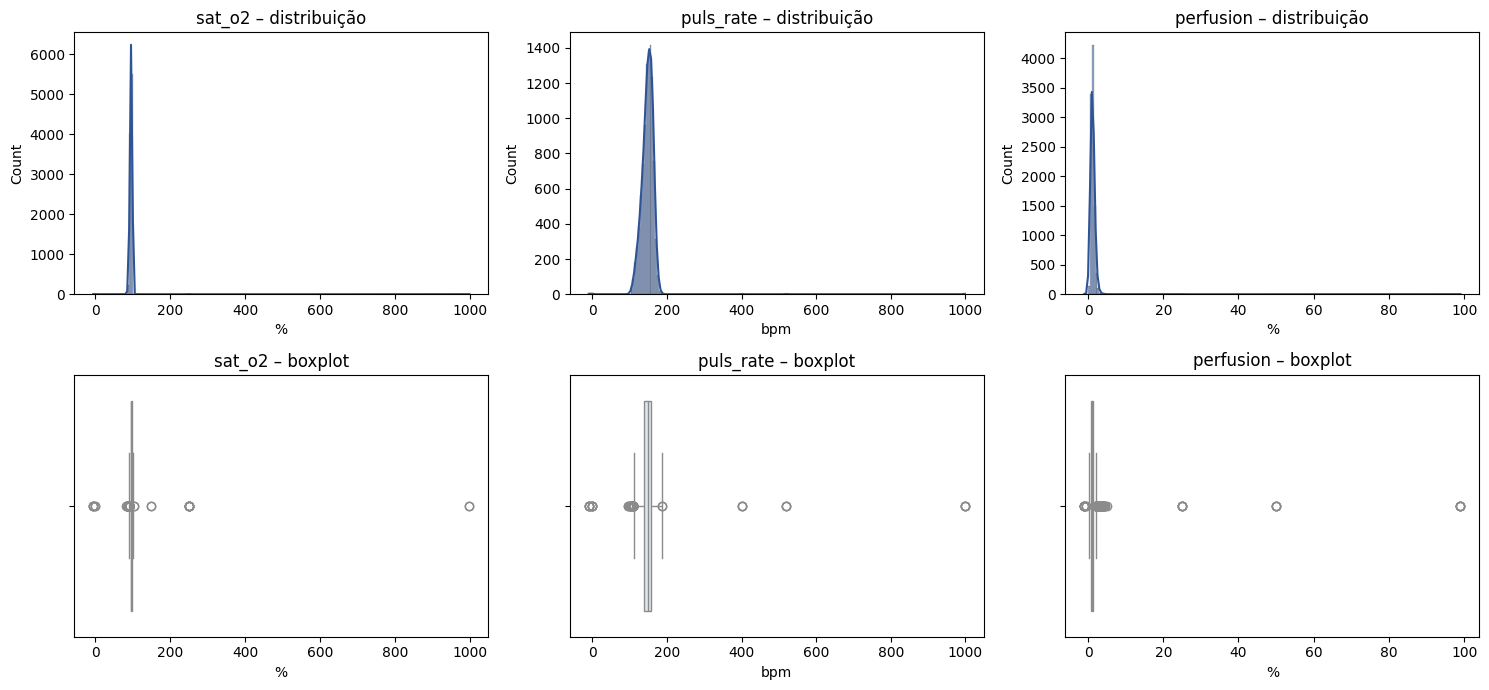

In [11]:
# =============================================================================
# 2.2.7 Visualização univariada dos sinais vitais (Passo 6)
# Histograma com curva de densidade (forma da distribuição) e boxplot
# (mediana, dispersão e possíveis outliers) para cada sinal vital.
# =============================================================================
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
unidades = {"sat_o2": "%", "puls_rate": "bpm", "perfusion": "%"}

for i, col in enumerate(VITAIS):
    sns.histplot(sv[col].dropna(), kde=True, ax=axes[0, i], color="#2F5496")
    axes[0, i].set_title(f"{col} – distribuição")
    axes[0, i].set_xlabel(unidades[col])
    sns.boxplot(x=sv[col].dropna(), ax=axes[1, i], color="#DCE6F2")
    axes[1, i].set_title(f"{col} – boxplot")
    axes[1, i].set_xlabel(unidades[col])

plt.tight_layout()
plt.show()

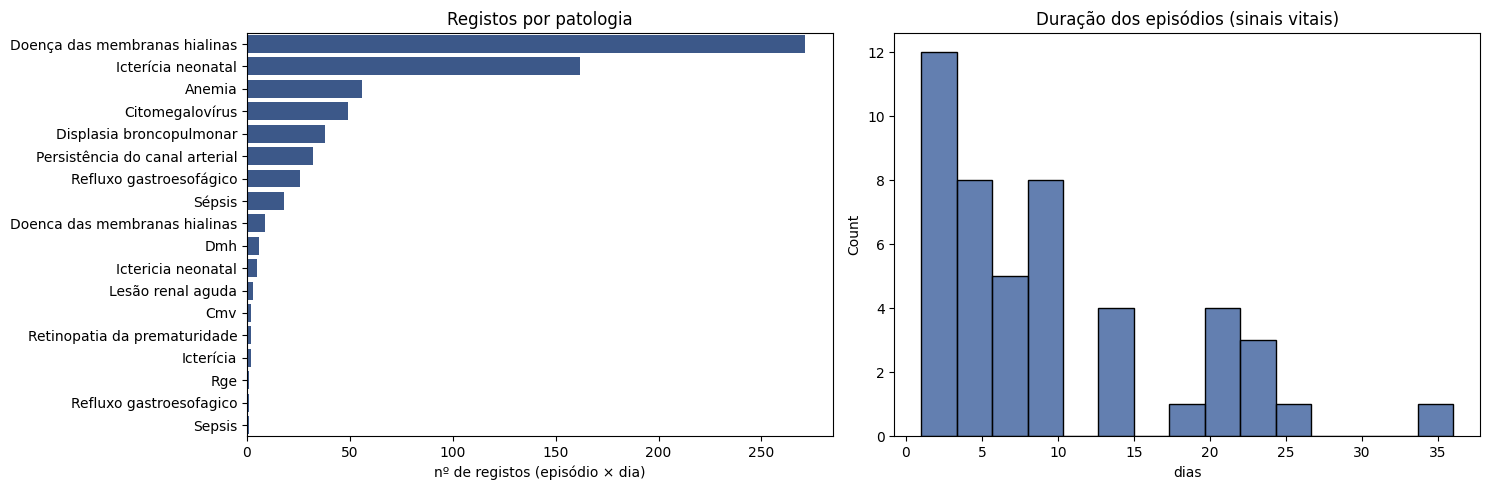

In [12]:
# =============================================================================
# 2.2.8 Visualização das patologias e da duração dos episódios (Passo 6)
# Esquerda: nº de registos por patologia (mostra o desequilíbrio entre classes)
# Direita: duração de cada episódio em dias (base da variável alvo da regressão)
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

freq = pat["patologia"].value_counts()
sns.barplot(x=freq.values, y=freq.index, ax=axes[0], color="#2F5496")
axes[0].set_title("Registos por patologia")
axes[0].set_xlabel("nº de registos (episódio × dia)")
axes[0].set_ylabel("")

sns.histplot(por_episodio["duracao_dias"], bins=15, ax=axes[1], color="#2F5496")
axes[1].set_title("Duração dos episódios (sinais vitais)")
axes[1].set_xlabel("dias")

plt.tight_layout()
plt.show()

sat_o2: 27 valores fora de [50, 100]
puls_rate: 20 valores fora de [50, 250]
perfusion: 23 valores fora de [0, 20]


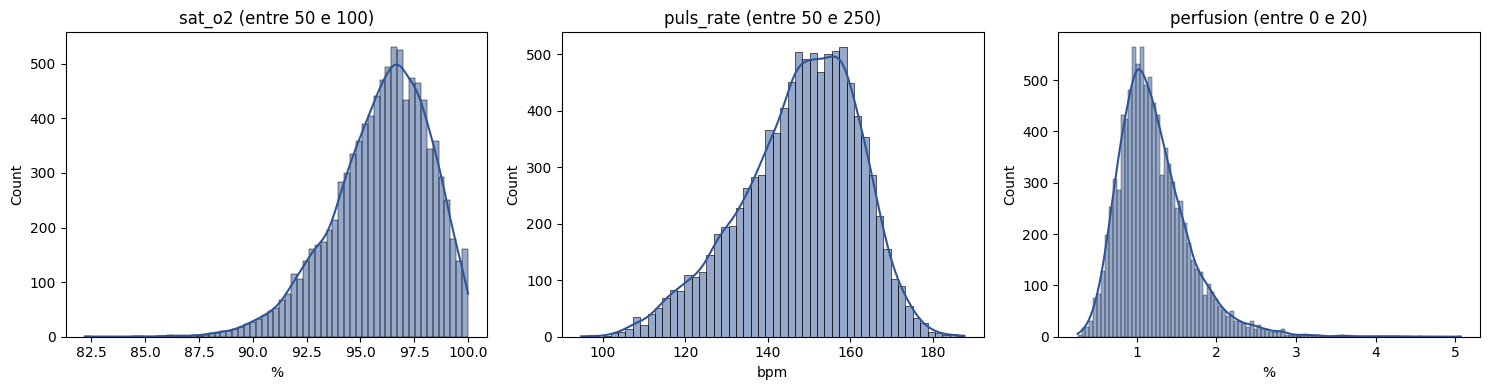

In [13]:
# =============================================================================
# 2.2.9 Distribuições dentro de limites fisiologicamente plausíveis (Passo 6)
# Os valores impossíveis (ex.: 999) achatam os gráficos anteriores.
# Aqui mostram-se só os valores dentro de limites plausíveis, para ver a forma
# real das distribuições. Os valores fora dos limites são contados e
# analisados na tarefa 2.4 (não são removidos).
# =============================================================================
LIMITES = {"sat_o2": (50, 100), "puls_rate": (50, 250), "perfusion": (0, 20)}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(VITAIS):
    lo, hi = LIMITES[col]
    dentro = sv[col].between(lo, hi)
    fora = sv[col].notna() & ~dentro
    print(f"{col}: {fora.sum()} valores fora de [{lo}, {hi}]")
    sns.histplot(sv.loc[dentro, col], kde=True, ax=axes[i], color="#2F5496")
    axes[i].set_title(f"{col} (entre {lo} e {hi})")
    axes[i].set_xlabel(unidades[col])

plt.tight_layout()
plt.show()

### Relatório de Descrição dos Dados

**Formato e quantidade**

| Tabela | Registos | Campos | Episódios (códigos normalizados) | Período |
|---|---|---|---|---|
| Sinais vitais | 9 857 | 6 | 47 | 30/01/2024 a 20/04/2024 |
| Patologias | 696 | 3 | 39 | 30/01/2024 a 20/04/2024 |

Depois de normalizados os códigos de episódio, existem **47 episódios**. Todos os episódios com patologias têm também sinais vitais e **8 episódios não têm qualquer patologia registada** (EP007, EP012, EP021, EP028, EP031, EP035, EP044 e EP047).

**Episódios**

Cada episódio tem, em mediana, 143 registos horários ao longo de 7 dias (mínimo 1 dia, máximo 36). O número de dias distintos com registos é praticamente igual à duração entre o primeiro e o último dia, o que indica uma monitorização contínua. A distribuição da duração tem cauda à direita: 12 episódios duram 3 dias ou menos e poucos ultrapassam 20 dias.

**Sinais vitais**

| Variável | Mediana | Q1 – Q3 | Mínimo | Máximo | Observação |
|---|---|---|---|---|---|
| sat_o2 (%) | 96,27 | 94,67 – 97,63 | −5 | 999 | Valores impossíveis (< 0 e > 100) |
| puls_rate (bpm) | 149,38 | 138,96 – 158,17 | −10 | 999 | Valores impossíveis (≤ 0, 400, 520, 999) |
| perfusion (%) | 1,15 | 0,91 – 1,44 | −1 | 99 | Valores suspeitos (< 0, 25, 50, 99) |

As medianas e os quartis são clinicamente plausíveis para recém-nascidos internados. Um pequeno número de valores impossíveis, possivelmente códigos de "valor desconhecido" como 999 e 99, distorce a média, o desvio padrão e a assimetria. Por isso, a mediana e os quartis são as medidas mais fiáveis nesta fase. Não foi possível converter para número 3 valores de sat_o2, 7 de puls_rate e 5 de perfusion.

Excluindo os valores impossíveis, as distribuições são clinicamente plausíveis. A sat_o2 concentra-se entre 92 % e 100 %, com pico perto de 97 %, cauda à esquerda e limite natural em 100 %. A puls_rate varia entre cerca de 100 e 185 bpm, com pico entre 145 e 160 bpm e ligeira assimetria à esquerda. A perfusion varia entre cerca de 0,3 % e 5 %, com pico em 1 % e cauda à direita.

**Hora**

Os registos distribuem-se de forma uniforme pelas 24 horas (401 a 420 por hora). Existem valores fora do domínio: −1 (5 registos), 24 (2) e 25 (1).

**Patologias**

Há 18 designações distintas, quando o domínio tem 13. As diferenças devem-se a nomes sem acentos ("Doenca das membranas hialinas", "Sepsis"), siglas ("Dmh", "Cmv", "Rge") e nomes incompletos ("Icterícia"). Agrupando as variantes, só 10 das 13 patologias aparecem nos dados. Hemorragia peri-intraventricular, enterocolite necrosante e doença metabólica óssea da prematuridade não têm registos. Existem 12 registos sem patologia.

As classes estão muito desequilibradas: a doença das membranas hialinas representa cerca de 42 % dos registos e a icterícia neonatal 25 %, enquanto a lesão renal aguda e a retinopatia da prematuridade têm 3 e 2 registos.

Dos 446 pares episódio-dia, cerca de 39 % têm duas ou mais patologias, o que confirma o carácter multi-label do problema (valor a confirmar após a correção das designações, já que variantes do mesmo nome são contadas como patologias distintas).

**Datas**

Existem 18 datas inválidas nos sinais vitais e 10 nas patologias, analisadas na tarefa 2.4.

**Níveis de análise**

As patologias são registadas por dia e variam ao longo do episódio, tal como os sinais vitais. Por isso, a classificação de patologias será feita ao nível do par episódio-dia (cerca de 446 exemplos). A duração do internamento e o clustering são características do episódio inteiro e serão analisados ao nível do episódio (47 exemplos).

**Os dados satisfazem os requisitos do projeto?**

| Objetivo | Avaliação |
|---|---|
| DM1 – Classificação | **Parcialmente.** Há cerca de 446 pares episódio-dia com patologias, mas só 10 das 13 patologias existem e algumas têm 2 ou 3 registos. Será necessário trabalhar apenas com as patologias mais frequentes ou agrupá-las. |
| DM2 – Regressão | **Com limitações.** A duração do internamento pode ser construída a partir das datas, mas, se for calculada por episódio, só há 47 exemplos. Alternativas a analisar na tarefa 2.3. |
| DM3 – Clustering | **Sim**, com 47 episódios caracterizados pelos sinais vitais e pelas patologias, embora seja uma amostra pequena. |
| Qualidade | Os problemas encontrados (códigos, nomes, valores impossíveis, datas e horas inválidas) são corrigíveis e serão detalhados na tarefa 2.4. |